In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

In [2]:
df=pd.read_csv(r"C:\Users\Afifa\OneDrive\Documents\project\archive\Student_performance_data _.csv")

In [3]:
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


In [4]:
print("Dataset shape:",df.shape)
print(df.columns.tolist())
df.info()

Dataset shape: (2392, 15)
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']
<class 'pandas.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12 

In [5]:
#missing values
print(df.isnull().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


In [6]:
#Duplicates
print("Duplicate Rows:",int(df.duplicated().sum()))
print("Duplicate Student IDs:",int(df["StudentID"].duplicated().sum()))
      

Duplicate Rows: 0
Duplicate Student IDs: 0


In [7]:
print("Age range:")
print(df["Age"].min(),"to",df["Age"].max())
print("\nGPA range:")
print(df["GPA"].min(),"to",df["GPA"].max())
print("\nStudy time:")
print(df["StudyTimeWeekly"].min(),"to",df["StudyTimeWeekly"].max())
print("\nAbsence range:")
print(df["Absences"].min(),"to",df["Absences"].max())

Age range:
15 to 18

GPA range:
0.0 to 4.0

Study time:
0.001056538645936 to 19.97809399526153

Absence range:
0 to 29


In [8]:
columns = [
    "Gender", "Ethnicity", "ParentalEducation",
    "ParentalSupport", "Tutoring",
    "Extracurricular", "Sports", "Music", "Volunteering"
]

for col in columns:
    print(f"\n{col}:")
    print(sorted(df[col].unique()))


Gender:
[np.int64(0), np.int64(1)]

Ethnicity:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3)]

ParentalEducation:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

ParentalSupport:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Tutoring:
[np.int64(0), np.int64(1)]

Extracurricular:
[np.int64(0), np.int64(1)]

Sports:
[np.int64(0), np.int64(1)]

Music:
[np.int64(0), np.int64(1)]

Volunteering:
[np.int64(0), np.int64(1)]


In [9]:
columns = ["GPA", "Absences", "StudyTimeWeekly"]

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\nColumn: {col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Number of outliers:", len(outliers))


Column: GPA
Q1: 1.1748034468836228
Q3: 2.622216170450785
IQR: 1.447412723567162
Lower limit: -0.9963156384671206
Upper limit: 4.793335255801528
Number of outliers: 0

Column: Absences
Q1: 7.0
Q3: 22.0
IQR: 15.0
Lower limit: -15.5
Upper limit: 44.5
Number of outliers: 0

Column: StudyTimeWeekly
Q1: 5.043079161539899
Q3: 14.408409547514031
IQR: 9.365330385974133
Lower limit: -9.004916417421299
Upper limit: 28.456405126475232
Number of outliers: 0


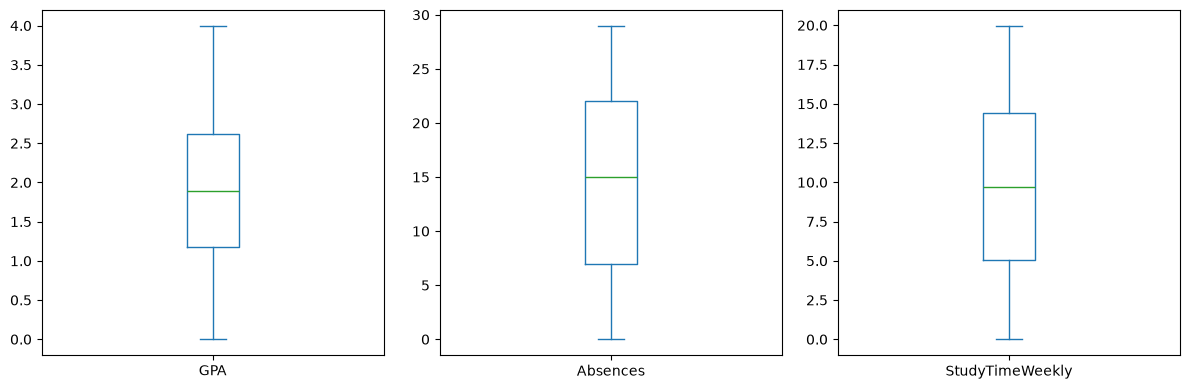

In [10]:
df[["GPA", "Absences", "StudyTimeWeekly"]].plot(
    kind="box",
    subplots=True,
    layout=(1, 3),
    figsize=(12, 4)
)

plt.tight_layout()
plt.show()

In [11]:
#cleaned copy
cleaned_df = df.copy()

# Final checks
print("Missing values:", cleaned_df.isnull().sum().sum())
print("Duplicate rows:", cleaned_df.duplicated().sum())
print("Duplicate Student IDs:",
      cleaned_df["StudentID"].duplicated().sum())

print("\nDataset shape:", cleaned_df.shape)

cleaned_df.head()

Missing values: 0
Duplicate rows: 0
Duplicate Student IDs: 0

Dataset shape: (2392, 15)


,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


In [12]:
cleaned_df.to_csv("Student_Performance_Cleaned.csv", index=False)

cleaned_df.to_excel("Student_Performance_Cleaned.xlsx", index=False)

print("Cleaned files saved successfully!")

Cleaned files saved successfully!


In [13]:
# KPI calculations
total_students = cleaned_df["StudentID"].nunique()
average_gpa = cleaned_df["GPA"].mean()
average_absences = cleaned_df["Absences"].mean()
average_study_time = cleaned_df["StudyTimeWeekly"].mean()
print("Total Students:", total_students)
print("Average GPA:", round(average_gpa, 2))
print("Average Absences:", round(average_absences, 2))
print("Average Weekly Study Time:", round(average_study_time, 2))

Total Students: 2392
Average GPA: 1.91
Average Absences: 14.54
Average Weekly Study Time: 9.77


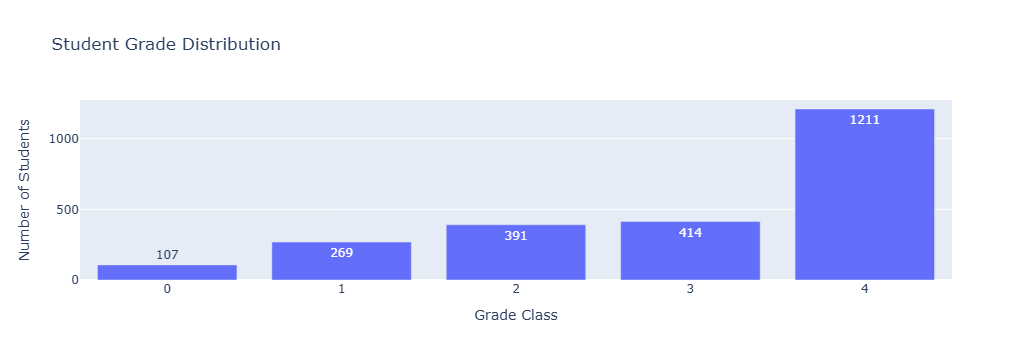

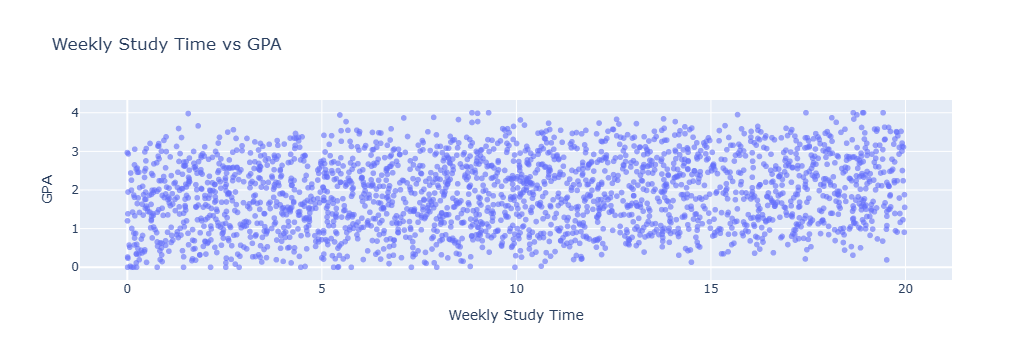

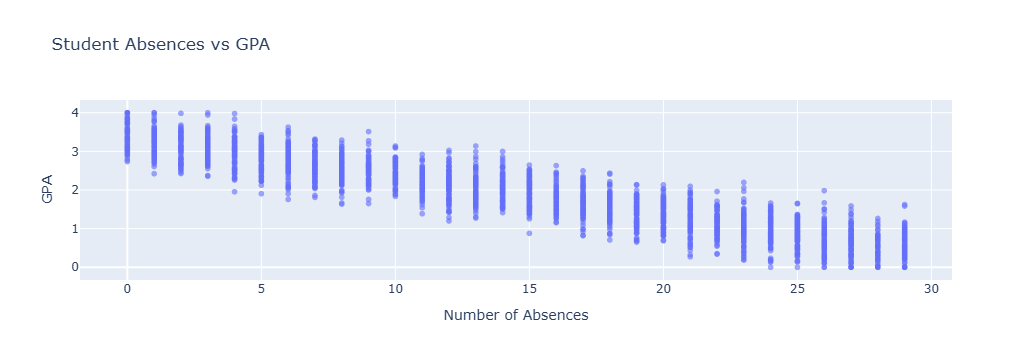

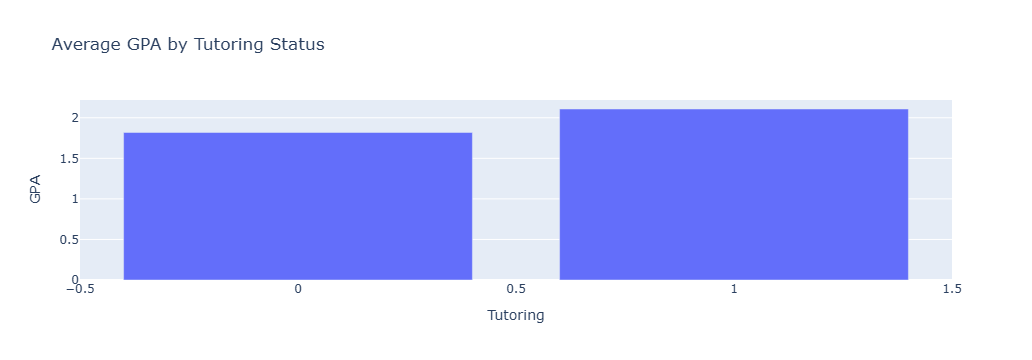

In [14]:

# 1. Grade Distribution
grade_counts = (
    cleaned_df["GradeClass"]
    .value_counts()
    .sort_index()
    .reset_index()
)
grade_counts.columns = ["GradeClass", "NumberOfStudents"]

fig1 = px.bar(
    grade_counts,
    x="GradeClass",
    y="NumberOfStudents",
    title="Student Grade Distribution",
    labels={
        "GradeClass": "Grade Class",
        "NumberOfStudents": "Number of Students"
    },
    text="NumberOfStudents"
)
fig1.show()


# 2. Weekly Study Time vs GPA
fig2 = px.scatter(
    cleaned_df,
    x="StudyTimeWeekly",
    y="GPA",
    title="Weekly Study Time vs GPA",
    labels={
        "StudyTimeWeekly": "Weekly Study Time",
        "GPA": "GPA"
    },
    opacity=0.6,
    hover_data=["StudentID"]
)
fig2.show()


# 3. Absences vs GPA
fig3 = px.scatter(
    cleaned_df,
    x="Absences",
    y="GPA",
    title="Student Absences vs GPA",
    labels={
        "Absences": "Number of Absences",
        "GPA": "GPA"
    },
    opacity=0.6,
    hover_data=["StudentID"]
)
fig3.show()


# Graph 4: Average GPA by tutoring status
tutoring_gpa = (
    cleaned_df.groupby("Tutoring", as_index=False)["GPA"]
    .mean()
)

fig4 = px.bar(
    tutoring_gpa,
    x="Tutoring",
    y="GPA",
    title="Average GPA by Tutoring Status"
)
fig4.show()

In [15]:
%pip install dash


Note: you may need to restart the kernel to use updated packages.


In [16]:
import dash
import plotly.express as px

print("Dash version:", dash.__version__)
print("Dash is ready!")

Dash version: 4.4.1
Dash is ready!


In [17]:
# If Dash is not installed, run this first:
# %pip install dash plotly pandas

import pandas as pd
import plotly.express as px
from dash import Dash, dcc, html, Input, Output

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------
try:
    df = cleaned_df.copy()
except NameError:
    df = pd.read_csv("Student_Performance_Cleaned.csv")

# Standardize column names
df.columns = df.columns.str.strip()

# Ensure numeric columns are numeric
numeric_cols = [
    "Age", "StudyTimeWeekly", "Absences", "GPA",
    "GradeClass", "Gender", "Tutoring"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["GPA", "StudyTimeWeekly", "Absences", "GradeClass"])

# Labels for binary categories
df["GenderLabel"] = df["Gender"].map({
    0: "Male", 1: "Female"
}).fillna(df["Gender"].astype(str))

df["TutoringLabel"] = df["Tutoring"].map({
    0: "No Tutoring", 1: "Tutoring"
}).fillna(df["Tutoring"].astype(str))

# Friendly grade labels
df["GradeLabel"] = df["GradeClass"].apply(
    lambda x: f"Class {int(x)}" if pd.notna(x) else "Unknown"
)

# --------------------------------------------------
# 2. CLASSIC PASTEL COLORS
# --------------------------------------------------
COLORS = {
    "background": "#FFF9F5",
    "card": "#FFFFFF",
    "text": "#45445A",
    "periwinkle": "#A9B8E8",
    "lavender": "#C8B6E2",
    "pink": "#F2B8C6",
    "blue": "#A9D3E8",
    "sage": "#B9D8C2",
    "peach": "#F4C7A1",
    "grid": "#EAE5E2"
}

GRADE_COLORS = [
    COLORS["periwinkle"],
    COLORS["lavender"],
    COLORS["pink"],
    COLORS["blue"],
    COLORS["sage"]
]

# --------------------------------------------------
# 3. DASH APP
# --------------------------------------------------
app = Dash(__name__)
app.title = "Student Performance Analytics"

def card_style():
    return {
        "backgroundColor": COLORS["card"],
        "borderRadius": "16px",
        "padding": "18px",
        "boxShadow": "0 3px 12px rgba(80,70,90,0.08)",
        "border": "1px solid #F0EAE7"
    }

def dropdown_style():
    return {
        "backgroundColor": "white",
        "borderRadius": "10px",
        "color": COLORS["text"]
    }

app.layout = html.Div(
    style={
        "backgroundColor": COLORS["background"],
        "minHeight": "100vh",
        "padding": "28px",
        "fontFamily": "Arial, sans-serif",
        "color": COLORS["text"]
    },
    children=[
        # Header
        html.Div([
            html.H1(
                "University Student Performance Analytics",
                style={"marginBottom": "6px", "color": COLORS["text"]}
            ),
            html.P(
                "Explore student grades, study habits, attendance, and tutoring.",
                style={"fontSize": "15px", "color": "#777487"}
            )
        ], style={"marginBottom": "24px"}),

        # Filters
        html.Div([
            html.Div([
                html.Label("Gender"),
                dcc.Dropdown(
                    id="gender-filter",
                    options=[{"label": x, "value": x}
                             for x in sorted(df["GenderLabel"].dropna().unique())],
                    value=None,
                    placeholder="All genders",
                    clearable=True,
                    style=dropdown_style()
                )
            ], style={"flex": "1"}),

            html.Div([
                html.Label("Tutoring"),
                dcc.Dropdown(
                    id="tutoring-filter",
                    options=[{"label": x, "value": x}
                             for x in sorted(df["TutoringLabel"].dropna().unique())],
                    value=None,
                    placeholder="All students",
                    clearable=True,
                    style=dropdown_style()
                )
            ], style={"flex": "1"}),

            html.Div([
                html.Label("Grade Class"),
                dcc.Dropdown(
                    id="grade-filter",
                    options=[{"label": x, "value": x}
                             for x in sorted(df["GradeLabel"].unique())],
                    value=None,
                    placeholder="All grade classes",
                    clearable=True,
                    style=dropdown_style()
                )
            ], style={"flex": "1"}),

            html.Div([
                html.Label("Weekly Study Time"),
                dcc.RangeSlider(
                    id="study-filter",
                    min=0,
                    max=max(1, int(df["StudyTimeWeekly"].max())),
                    step=1,
                    value=[
                        int(df["StudyTimeWeekly"].min()),
                        int(df["StudyTimeWeekly"].max())
                    ],
                    marks=None,
                    tooltip={"placement": "bottom", "always_visible": True}
                )
            ], style={"flex": "1.5", "padding": "0 12px"})
        ], style={
            **card_style(),
            "display": "flex",
            "gap": "20px",
            "flexWrap": "wrap",
            "marginBottom": "22px"
        }),

        # KPI cards
        html.Div(id="kpi-cards", style={
            "display": "grid",
            "gridTemplateColumns": "repeat(4, minmax(150px, 1fr))",
            "gap": "16px",
            "marginBottom": "22px"
        }),

        # Charts
        html.Div([
            html.Div([
                dcc.Graph(id="grade-chart", config={"displayModeBar": False})
            ], style=card_style()),

            html.Div([
                dcc.Graph(id="study-chart", config={"displayModeBar": False})
            ], style=card_style()),

            html.Div([
                dcc.Graph(id="absence-chart", config={"displayModeBar": False})
            ], style=card_style()),

            html.Div([
                dcc.Graph(id="tutoring-chart", config={"displayModeBar": False})
            ], style=card_style())
        ], style={
            "display": "grid",
            "gridTemplateColumns": "repeat(2, minmax(0, 1fr))",
            "gap": "20px"
        })
    ]
)

# --------------------------------------------------
# 4. FILTER DATA AND UPDATE DASHBOARD
# --------------------------------------------------
@app.callback(
    Output("kpi-cards", "children"),
    Output("grade-chart", "figure"),
    Output("study-chart", "figure"),
    Output("absence-chart", "figure"),
    Output("tutoring-chart", "figure"),
    Input("gender-filter", "value"),
    Input("tutoring-filter", "value"),
    Input("grade-filter", "value"),
    Input("study-filter", "value")
)
def update_dashboard(gender, tutoring, grade, study_range):

    filtered = df.copy()

    if gender:
        filtered = filtered[filtered["GenderLabel"] == gender]

    if tutoring:
        filtered = filtered[filtered["TutoringLabel"] == tutoring]

    if grade:
        filtered = filtered[filtered["GradeLabel"] == grade]

    if study_range:
        filtered = filtered[
            filtered["StudyTimeWeekly"].between(
                study_range[0], study_range[1]
            )
        ]

    # --------------------------------------------------
    # KPI CARDS
    # --------------------------------------------------
    total_students = len(filtered)
    avg_gpa = filtered["GPA"].mean() if total_students else 0
    avg_absences = filtered["Absences"].mean() if total_students else 0
    avg_study = filtered["StudyTimeWeekly"].mean() if total_students else 0

    kpi_data = [
        ("Total Students", f"{total_students:,}", COLORS["periwinkle"]),
        ("Average GPA", f"{avg_gpa:.2f}", COLORS["lavender"]),
        ("Average Absences", f"{avg_absences:.1f}", COLORS["pink"]),
        ("Weekly Study Time", f"{avg_study:.1f} hrs", COLORS["blue"])
    ]

    kpis = []
    for title, value, color in kpi_data:
        kpis.append(
            html.Div([
                html.P(title, style={
                    "margin": "0",
                    "fontSize": "14px",
                    "color": "#777487"
                }),
                html.H2(value, style={
                    "margin": "8px 0 0",
                    "fontSize": "28px",
                    "color": COLORS["text"]
                })
            ], style={
                **card_style(),
                "borderTop": f"5px solid {color}"
            })
        )

    # Common chart layout
    def style_chart(fig):
        fig.update_layout(
            paper_bgcolor="white",
            plot_bgcolor="white",
            font=dict(color=COLORS["text"], family="Arial"),
            margin=dict(l=45, r=20, t=65, b=45),
            title=dict(font=dict(size=17)),
            xaxis=dict(showgrid=False, title_font=dict(size=12)),
            yaxis=dict(
                showgrid=True,
                gridcolor=COLORS["grid"],
                title_font=dict(size=12)
            ),
            showlegend=False
        )
        return fig

    # --------------------------------------------------
    # CHART 1: NUMBER OF STUDENTS IN EACH GRADE CLASS
    # --------------------------------------------------
    grade_summary = (
        filtered.groupby("GradeLabel")
        .size()
        .reset_index(name="Students")
        .sort_values("GradeLabel")
    )

    grade_fig = px.bar(
        grade_summary,
        x="GradeLabel",
        y="Students",
        title="Number of Students by Grade Class",
        color="GradeLabel",
        color_discrete_sequence=GRADE_COLORS,
        text="Students"
    )

    grade_fig.update_traces(
        textposition="outside",
        cliponaxis=False
    )
    grade_fig.update_xaxes(title="Grade Class")
    grade_fig.update_yaxes(title="Number of Students")
    style_chart(grade_fig)

    # --------------------------------------------------
    # CHART 2: AVERAGE GPA BY WEEKLY STUDY TIME RANGE
    # --------------------------------------------------
    study_bins = [0, 5, 10, 15, 20, 100]
    study_labels = ["0–5", "5–10", "10–15", "15–20", "20+"]

    study_data = filtered.copy()
    study_data["StudyRange"] = pd.cut(
        study_data["StudyTimeWeekly"],
        bins=study_bins,
        labels=study_labels,
        include_lowest=True,
        right=False
    )

    study_summary = (
        study_data.groupby("StudyRange", observed=False)
        .agg(AvgGPA=("GPA", "mean"), Students=("GPA", "count"))
        .reset_index()
        .dropna(subset=["AvgGPA"])
    )

    study_fig = px.bar(
        study_summary,
        x="StudyRange",
        y="AvgGPA",
        title="Average GPA by Weekly Study Time",
        color="StudyRange",
        color_discrete_sequence=[
            COLORS["blue"], COLORS["periwinkle"],
            COLORS["lavender"], COLORS["pink"], COLORS["sage"]
        ],
        text=study_summary["AvgGPA"].round(2)
    )

    study_fig.update_traces(textposition="outside", cliponaxis=False)
    study_fig.update_xaxes(title="Study Hours per Week")
    study_fig.update_yaxes(title="Average GPA")
    style_chart(study_fig)

    # --------------------------------------------------
    # CHART 3: AVERAGE GPA BY ABSENCE RANGE
    # --------------------------------------------------
    absence_bins = [-1, 5, 10, 15, 1000]
    absence_labels = ["0–5", "6–10", "11–15", "16+"]

    absence_data = filtered.copy()
    absence_data["AbsenceRange"] = pd.cut(
        absence_data["Absences"],
        bins=absence_bins,
        labels=absence_labels,
        include_lowest=True
    )

    absence_summary = (
        absence_data.groupby("AbsenceRange", observed=False)
        .agg(AvgGPA=("GPA", "mean"), Students=("GPA", "count"))
        .reset_index()
        .dropna(subset=["AvgGPA"])
    )

    absence_fig = px.bar(
        absence_summary,
        x="AbsenceRange",
        y="AvgGPA",
        title="Average GPA by Absence Range",
        color="AbsenceRange",
        color_discrete_sequence=[
            COLORS["sage"], COLORS["blue"],
            COLORS["peach"], COLORS["pink"]
        ],
        text=absence_summary["AvgGPA"].round(2)
    )

    absence_fig.update_traces(textposition="outside", cliponaxis=False)
    absence_fig.update_xaxes(title="Number of Absences")
    absence_fig.update_yaxes(title="Average GPA")
    style_chart(absence_fig)

    # --------------------------------------------------
    # CHART 4: GPA WITH AND WITHOUT TUTORING
    # --------------------------------------------------
    tutoring_summary = (
        filtered.groupby("TutoringLabel")
        .agg(AvgGPA=("GPA", "mean"), Students=("GPA", "count"))
        .reset_index()
    )

    tutoring_fig = px.bar(
        tutoring_summary,
        x="TutoringLabel",
        y="AvgGPA",
        title="Average GPA: Tutoring Comparison",
        color="TutoringLabel",
        color_discrete_map={
            "No Tutoring": COLORS["peach"],
            "Tutoring": COLORS["lavender"]
        },
        text=tutoring_summary["AvgGPA"].round(2)
    )

    tutoring_fig.update_traces(textposition="outside", cliponaxis=False)
    tutoring_fig.update_xaxes(title="Tutoring")
    tutoring_fig.update_yaxes(title="Average GPA")
    style_chart(tutoring_fig)

    return kpis, grade_fig, study_fig, absence_fig, tutoring_fig


# --------------------------------------------------
# 5. RUN DASH APP
# --------------------------------------------------
if __name__ == "__main__":
    app.run(debug=True, port=8050)

SyntaxError: invalid syntax (1625976544.py, line 1)